# **Nama: Andika Dinata**
# **NIM: 123140096**

In [35]:
!pip install torch torchvision pillow matplotlib scikit-learn

## Download gambar

In [36]:
import urllib.request
from pathlib import Path

IMAGES = {
    "hewan_cat_a_landscape.jpg": "https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?q=80&w=1143&auto=format&fit=crop&ixlib=rb-4.1.0",
    "hewan_cat_b_landscape.jpg": "https://images.unsplash.com/photo-1478098711619-5ab0b478d6e6?q=80&w=1170&auto=format&fit=crop&ixlib=rb-4.1.0",
    "hewan_racoon_a_landscape.jpg": "https://images.unsplash.com/photo-1497752531616-c3afd9760a11?q=80&w=1170&auto=format&fit=crop&ixlib=rb-4.1.0",
    "hewan_racoon_b_potrait.jpg": "https://images.unsplash.com/photo-1628044582571-1b2615cc451a?q=80&w=687&auto=format&fit=crop&ixlib=rb-4.1.0",
    "hewan_cat_c_potrait.jpg": "https://plus.unsplash.com/premium_photo-1673967831980-1d377baaded2?q=80&w=687&auto=format&fit=crop&ixlib=rb-4.1.0",
    "kendaraan_car_a_potrait.jpg": "https://images.unsplash.com/photo-1516298252535-cf2ac5147f9b?q=80&w=687&auto=format&fit=crop&ixlib=rb-4.1.0",
    "kendaraan_car_b_potrait.jpg": "https://images.unsplash.com/photo-1656533498028-2d06ade429f0?w=500&auto=format&fit=crop&q=60&ixlib=rb-4.1.0",
    "kendaraan_motorcycle_potrait.jpg": "https://images.unsplash.com/photo-1663330082092-11fa01e1ee8e?w=500&auto=format&fit=crop&q=60&ixlib=rb-4.1.0",
    "makanan_burger_a_landscape.jpg": "https://images.unsplash.com/photo-1568901346375-23c9450c58cd?q=80&w=999&auto=format&fit=crop&ixlib=rb-4.1.0",
    "makanan_burger_b_landscape.jpg": "https://images.unsplash.com/photo-1572802419224-296b0aeee0d9?q=80&w=1115&auto=format&fit=crop&ixlib=rb-4.1.0",
    "makanan_pizza_landscape.jpg": "https://images.unsplash.com/photo-1574071318508-1cdbab80d002?q=80&w=1169&auto=format&fit=crop&ixlib=rb-4.1.0",
}

OUT_DIR = Path("data")
OUT_DIR.mkdir(exist_ok=True)
headers = {"User-Agent": "Mozilla/5.0"}

for filename, url in IMAGES.items():
    out_path = OUT_DIR / filename
    if out_path.exists():
        print(f"[SKIP] {filename} (sudah ada)")
        continue
    try:
        req = urllib.request.Request(url, headers=headers)
        with urllib.request.urlopen(req) as response, open(out_path, "wb") as f:
            f.write(response.read())
        print(f"[OK]   {filename}")
    except Exception as e:
        print(f"[GAGAL] {filename}: {e}")

print(f"\nSelesai. Total {len(IMAGES)} gambar di folder \'{OUT_DIR}/\'")

[SKIP] hewan_cat_a_landscape.jpg (sudah ada)
[SKIP] hewan_cat_b_landscape.jpg (sudah ada)
[SKIP] hewan_racoon_a_landscape.jpg (sudah ada)
[SKIP] hewan_racoon_b_potrait.jpg (sudah ada)
[SKIP] hewan_cat_c_potrait.jpg (sudah ada)
[SKIP] kendaraan_car_a_potrait.jpg (sudah ada)
[SKIP] kendaraan_car_b_potrait.jpg (sudah ada)
[SKIP] kendaraan_motorcycle_potrait.jpg (sudah ada)
[SKIP] makanan_burger_a_landscape.jpg (sudah ada)
[SKIP] makanan_burger_b_landscape.jpg (sudah ada)
[SKIP] makanan_pizza_landscape.jpg (sudah ada)

Selesai. Total 11 gambar di folder 'data/'


## Persiapan

In [37]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from torchvision.models import ResNet50_Weights, resnet50
from sklearn.decomposition import PCA

torch.manual_seed(0)
DATA_DIR = Path("data")
print("Setup selesai. Folder data:", DATA_DIR.resolve())

Setup selesai. Folder data: /content/data


## Soal 1: Gambar sebagai Tensor RGB

### a. Pilih dua gambar lokal dengan ukuran atau rasio aspek yang berbeda. Muat gambar menggunakan Pillow, lalu tampilkan: ukuran asli setiap gambar, mode warna, jumlah kanal, rasio aspek.

In [38]:
paths = [DATA_DIR / "hewan_racoon_b_potrait.jpg", DATA_DIR / "makanan_burger_a_landscape.jpg"]
images_s1 = [Image.open(p).convert("RGB") for p in paths]

for path, image in zip(paths, images_s1):
    width, height = image.size
    print(f"--- {path.name} ---")
    print("Ukuran asli (W x H):", image.size)
    print("Mode warna:", image.mode)
    print("Jumlah kanal:", len(image.getbands()))
    print("Rasio aspek (W/H):", round(width / height, 3))
    print()

--- hewan_racoon_b_potrait.jpg ---
Ukuran asli (W x H): (687, 1030)
Mode warna: RGB
Jumlah kanal: 3
Rasio aspek (W/H): 0.667

--- makanan_burger_a_landscape.jpg ---
Ukuran asli (W x H): (999, 830)
Mode warna: RGB
Jumlah kanal: 3
Rasio aspek (W/H): 1.204



### b. Tampilkan kedua gambar menggunakan matplotlib dan jelaskan perbedaan visualnya secara singkat.

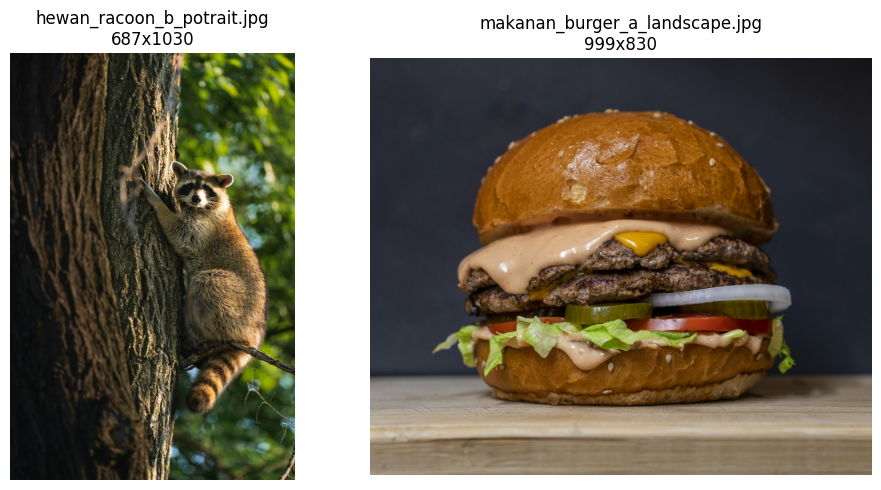

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for axis, path, image in zip(axes, paths, images_s1):
    axis.imshow(image)
    axis.set_title(f"{path.name}\n{image.size[0]}x{image.size[1]}")
    axis.axis("off")
plt.tight_layout()
plt.savefig("mgg03_tugas_01.jpg", dpi=150)
plt.show()

Kedua gambar memiliki perbedaan aspect ratio, orientasi (potrait vs landskap), dan komposisinya juga berbeda. Rakun mengisi sebagian besar frame, sedangkan burger tepat berada di tengah gambar.

### c. Analisis

**Mengapa gambar tidak cukup direpresentasikan sebagai daftar angka tanpa struktur spasial?**

Gambar bukan hanya kumpulan angka piksel, tetapi juga memiliki hubungan antar piksel yang berdekatan. Hubungan ini penting untuk mengenali pola seperti tepi, tekstur, dan bentuk. Jika gambar di-*flatten* menjadi vektor 1D, posisi dan hubungan antar piksel akan hilang sehingga pola lokal sulit dideteksi. Karena itu, bentuk H×W×C diperlukan agar informasi posisi piksel tetap terjaga.

**Apa konsekuensi perbedaan ukuran dan rasio aspek sebelum gambar diproses CNN?**

CNN membutuhkan ukuran input yang sesuai dengan arsitekturnya. Karena itu, gambar dengan ukuran atau rasio aspek berbeda biasanya perlu di-*resize* atau di-*crop*. *Resize* yang tidak mempertahankan rasio dapat membuat objek terlihat tidak proporsional, sedangkan *crop* dapat menghilangkan bagian penting dari gambar.

**Mengapa gambar RGB memiliki C = 3?**

Karena RGB terdiri dari tiga kanal warna, yaitu merah, hijau, dan biru. Ketiga kanal ini menyimpan informasi warna pada setiap piksel. Dengan tiga kanal tersebut, CNN dapat mempelajari pola warna selain hanya tingkat kecerahan seperti pada gambar grayscale.


# Soal 2:  Konvolusi 2D dan Pooling

### a. Hitung satu nilai keluaran y(1, 0) secara manual: ambil jendela 3 x 3 dari patch[1:4,0:3], kalikan elemen demi elemen dengan ky, lalu jumlahkan. Tuliskan langkah aritmetika-nya, bukan hanya hasil akhirnya.

In [40]:
patch = np.array([[0, 0, 0, 0, 0, 0],
                   [0, 0, 0, 0, 0, 0],
                   [0, 0, 0, 0, 0, 0],
                   [1, 1, 1, 1, 1, 1],
                   [1, 1, 1, 1, 1, 1],
                   [1, 1, 1, 1, 1, 1]], dtype=np.float32)

kernel_y = np.array([[-1, -2, -1],
                      [ 0,  0,  0],
                      [ 1,  2,  1]], dtype=np.float32)

kernel_x = np.array([[-1, 0, 1],
                      [-2, 0, 2],
                      [-1, 0, 1]], dtype=np.float32)

# window untuk y(1,0): baris 1-3, kolom 0-2
window = patch[1:4, 0:3]
print("Jendela patch[1:4, 0:3]:")
print(window)

elementwise = window * kernel_y
print("\nHasil perkalian elemen demi elemen dengan ky:")
print(elementwise)

y_1_0 = elementwise.sum()
print("\ny(1,0) = jumlah seluruh elemen di atas =", y_1_0)


Jendela patch[1:4, 0:3]:
[[0. 0. 0.]
 [0. 0. 0.]
 [1. 1. 1.]]

Hasil perkalian elemen demi elemen dengan ky:
[[-0. -0. -0.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]

y(1,0) = jumlah seluruh elemen di atas = 4.0


**Langkah aritmetika:**

window = [[0,0,0],[0,0,0],[1,1,1]], dikalikan elemen-demi-elemen dengan ky = [[-1,-2,-1],[0,0,0],[1,2,1]] menghasilkan [[0,0,0],[0,0,0],[1,2,1]].

Jumlah seluruh elemen = 0+0+0+0+0+0+1+2+1 = **4**

### b. Hitung seluruh feature map untuk ky dengan perulangan bersarang (for ganda) memakai numpy, lalu bandingkan dengan hasil torch.nn.functional.conv2d. Tampilkan kedua matriks dan selisih maksimumnya

In [41]:
H, W = patch.shape
K = kernel_y.shape[0]
feature = np.zeros((H - K + 1, W - K + 1), dtype=np.float32)

for i in range(feature.shape[0]):
    for j in range(feature.shape[1]):
        feature[i, j] = (patch[i:i+K, j:j+K] * kernel_y).sum()

tensor = torch.from_numpy(patch)[None, None]
weight = torch.from_numpy(kernel_y)[None, None]
library = F.conv2d(tensor, weight)[0, 0].numpy()

print("Feature map (manual, for-loop):")
print(feature)
print("\nFeature map (library, F.conv2d):")
print(library)
print("\nSelisih maksimum:", np.abs(feature - library).max())


Feature map (manual, for-loop):
[[0. 0. 0. 0.]
 [4. 4. 4. 4.]
 [4. 4. 4. 4.]
 [0. 0. 0. 0.]]

Feature map (library, F.conv2d):
[[0. 0. 0. 0.]
 [4. 4. 4. 4.]
 [4. 4. 4. 4.]
 [0. 0. 0. 0.]]

Selisih maksimum: 0.0


Feature map hasil for-loop manual identik dengan hasil `F.conv2d` (selisih maksimum 0.0), sesuai nilai pemeriksaan mandiri: bernilai 4 pada dua baris tengah dan nol pada baris teratas/terbawah, tepat pada posisi tepi horizontal antara baris gelap dan terang.

### c. Untuk masukan 6 × 6 dan kernel 3 × 3, hitung ukuran keluaran dengan rumus Hout =⌊︃ H − K + 2P S⌋︃ + 1 untuk tiga konfigurasi: (P =0, S=1), (P =1, S=1), dan (P =1, S=2). Verifikasi setiap nilai dengan memeriksa .shape hasil conv2d.

In [42]:
def out_size(H_in, K, P, S):
    return (H_in - K + 2 * P) // S + 1

configs = [(0, 1), (1, 1), (1, 2)]
for P, S in configs:
    predicted = out_size(6, 3, P, S)
    actual = F.conv2d(tensor, weight, padding=P, stride=S).shape[-1]
    print(f"P={P}, S={S} -> prediksi rumus: {predicted}x{predicted}, hasil conv2d.shape: {actual}x{actual}, cocok: {predicted == actual}")


P=0, S=1 -> prediksi rumus: 4x4, hasil conv2d.shape: 4x4, cocok: True
P=1, S=1 -> prediksi rumus: 6x6, hasil conv2d.shape: 6x6, cocok: True
P=1, S=2 -> prediksi rumus: 3x3, hasil conv2d.shape: 3x3, cocok: True


Ketiga konfigurasi terverifikasi cocok antara rumus dan `.shape` hasil `conv2d`:
- **(P=0, S=1):** 4×4 — tanpa padding, keluaran menyusut karena kernel 3×3 hanya dapat digeser 4 posisi pada sisi 6.
- **(P=1, S=1):** 6×6 — padding 1 menambah 1 piksel di tiap sisi sehingga ukuran keluaran sama dengan ukuran masukan (*same padding*).
- **(P=1, S=2):** 3×3 — stride 2 melompati satu posisi setiap pergeseran, sehingga jumlah posisi valid berkurang setengahnya dibanding S=1.

### d. Terapkan max pooling 2 × 2 pada feature map ky. Laporkan bentuk sebelum dan sesu-dahnya, serta nilai yang bertahan.

In [43]:
def maxpool2x2(fm, stride=2, k=2):
    Ho, Wo = fm.shape[0] // stride, fm.shape[1] // stride
    out = np.zeros((Ho, Wo), dtype=np.float32)
    for i in range(Ho):
        for j in range(Wo):
            out[i, j] = fm[i*stride:i*stride+k, j*stride:j*stride+k].max()
    return out

pooled = maxpool2x2(feature)
print("Bentuk sebelum pooling:", feature.shape)
print("Bentuk sesudah pooling:", pooled.shape)
print("\nHasil pooling:")
print(pooled)


Bentuk sebelum pooling: (4, 4)
Bentuk sesudah pooling: (2, 2)

Hasil pooling:
[[4. 4.]
 [4. 4.]]


Bentuk berubah dari **4x4 menjadi 2x2**, dan seluruh nilai yang bertahan adalah **4**, sesuai pemeriksaan mandiri. Ini karena setiap jendela pooling 2x2 pada feature map hanya berisi nilai 0 dan 4, sehingga operasi *max* selalu memilih 4.

### e. Jalankan langkah (b) dengan kx sebagai ganti ky. Jelaskan mengapa hasilnya nol di seluruh posisi, padahal pada (b) tidak demikian. Kaitkan jawaban Anda dengan gagasan bahwa kernel memilih pola tertentu.

In [44]:
feature_x = np.zeros((H - K + 1, W - K + 1), dtype=np.float32)
for i in range(feature_x.shape[0]):
    for j in range(feature_x.shape[1]):
        feature_x[i, j] = (patch[i:i+K, j:j+K] * kernel_x).sum()

print("Feature map dengan kx:")
print(feature_x)


Feature map dengan kx:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


**Mengapa hasilnya nol di seluruh posisi?**

Kernel `kx` digunakan untuk mendeteksi tepi vertikal, yaitu perubahan intensitas dari kiri ke kanan. Pada *patch* ini, perubahan intensitasnya justru terjadi dari atas ke bawah, sehingga `kx` tidak menemukan perubahan horizontal dan hasilnya nol.

Sebaliknya, `ky` dapat mendeteksi perubahan tersebut karena bekerja pada arah vertikal. Jadi, setiap kernel hanya akan memberikan respons jika pola pada gambar sesuai dengan pola yang ingin dideteksinya.


### f. Bandingkan jumlah parameter sebuah fully connected layer yang memetakan masukan 64 × 64 × 3 ke 64 unit dengan sebuah lapisan konvolusi yang memakai 64 filter 3 × 3 (abaikan bias). Jelaskan mengapa parameter sharing membuat konvolusi lebih layak dipakai pada gambar.

In [45]:
input_shape = (64, 64, 3)  # H, W, C
fc_units = 64

fc_params = input_shape[0] * input_shape[1] * input_shape[2] * fc_units
print("Parameter fully connected (64x64x3 -> 64 unit):", fc_params)

num_filters = 64
kernel_size = 3
conv_params = kernel_size * kernel_size * input_shape[2] * num_filters
print("Parameter konvolusi (64 filter 3x3, abaikan bias):", conv_params)

print(f"\nFC memiliki {fc_params / conv_params:.1f}x lebih banyak parameter daripada konvolusi.")


Parameter fully connected (64x64x3 -> 64 unit): 786432
Parameter konvolusi (64 filter 3x3, abaikan bias): 1728

FC memiliki 455.1x lebih banyak parameter daripada konvolusi.


Lapisan *fully connected* yang menghubungkan 64x64x3 = 12.288 nilai ke 64 unit membutuhkan **786.432 parameter**. Sementara itu, lapisan konvolusi dengan 64 filter berukuran 3x3 hanya membutuhkan **1.728 parameter**.

Perbedaannya karena konvolusi menggunakan *parameter sharing*, yaitu satu kernel yang sama digunakan di berbagai posisi gambar. Hal ini membuat jumlah parameter jauh lebih sedikit, mengurangi risiko *overfitting*, dan cocok untuk gambar karena pola seperti tepi bisa muncul di posisi mana saja.


# Soal 3:  ResNet50 sebagai Feature Extractor

### a sampai c: Muat weights ResNet50 dan ubah classifier terakhir menjadi torch.nn.Identity().

In [46]:
weights = ResNet50_Weights.DEFAULT
backbone = resnet50(weights=weights)
backbone.fc = torch.nn.Identity()
backbone.eval()

preprocess = weights.transforms()

features_s1 = []
with torch.inference_mode():
    for image in images_s1:
        tensor_in = preprocess(image).unsqueeze(0)
        feat = backbone(tensor_in).squeeze(0)
        features_s1.append(feat)
        print("feature shape:", tuple(feat.shape))


feature shape: (2048,)
feature shape: (2048,)


### d. Analisis

**Mengapa classifier terakhir dilepas?**

Lapisan `fc` pada ResNet50 digunakan untuk klasifikasi 1000 kelas ImageNet. Karena di sini model hanya digunakan untuk mengambil fitur gambar, lapisan tersebut diganti dengan `torch.nn.Identity()`. Dengan begitu, keluaran model berupa vektor fitur 2048 dimensi yang bisa digunakan untuk membandingkan gambar.

**Mengapa menggunakan `eval()` dan `torch.inference_mode()`?**

`eval()` digunakan agar lapisan seperti *dropout* dan *batch normalization* bekerja dalam mode inferensi. Sementara itu, `torch.inference_mode()` membuat PyTorch tidak menghitung gradien sehingga proses lebih cepat dan hemat memori. Keduanya sesuai karena model hanya digunakan untuk *forward pass*, bukan untuk dilatih.

**Mengapa keluaran backbone berupa vektor?**

Selama prosesnya, konvolusi dan *pooling* mengecilkan ukuran spasial gambar. Kemudian *global average pooling* merangkum setiap *feature map* menjadi satu nilai. Hasil akhirnya adalah vektor 2048 dimensi yang menyimpan informasi visual seperti bentuk, tekstur, dan pola. Vektor ini disebut *embedding* dan dapat digunakan untuk membandingkan gambar.


#  Soal 4: Kemiripan Kosinus Antar-Gambar

### a sampai b: Menghitung cosine similarity untuk dua pasangan gambar

In [47]:
# Pasangan A: dua kucing (diharapkan mirip)
# Pasangan B: kucing vs mobil (diharapkan berbeda)
pair_paths = {
    "A (mirip)": [DATA_DIR / "hewan_cat_a_landscape.jpg", DATA_DIR / "hewan_cat_b_landscape.jpg"],
    "B (berbeda)": [DATA_DIR / "hewan_cat_a_landscape.jpg", DATA_DIR / "kendaraan_car_a_potrait.jpg"],
}

results = {}
with torch.inference_mode():
    for label, (p1, p2) in pair_paths.items():
        img1 = Image.open(p1).convert("RGB")
        img2 = Image.open(p2).convert("RGB")
        f1 = backbone(preprocess(img1).unsqueeze(0)).squeeze(0)
        f2 = backbone(preprocess(img2).unsqueeze(0)).squeeze(0)
        sim = F.cosine_similarity(f1.unsqueeze(0), f2.unsqueeze(0)).item()
        results[label] = (p1.name, p2.name, sim)
        print(f"Pasangan {label}: {p1.name} vs {p2.name} -> cosine similarity = {sim:.4f}")


Pasangan A (mirip): hewan_cat_a_landscape.jpg vs hewan_cat_b_landscape.jpg -> cosine similarity = 0.4248
Pasangan B (berbeda): hewan_cat_a_landscape.jpg vs kendaraan_car_a_potrait.jpg -> cosine similarity = 0.0865


### c. Tabel hasil

In [48]:
import pandas as pd

data = []
for label, (n1, n2, sim) in results.items():
    desc = f"{n1} vs {n2}"
    interp = "Sangat mirip" if sim > 0.7 else ("Cukup mirip" if sim > 0.4 else "Berbeda")
    data.append({
        "Pasangan": label,
        "Deskripsi visual": desc,
        "Cosine sim.": f"{sim:.4f}",
        "Interpretasi": interp
    })

df = pd.DataFrame(data)
print(df.to_string(index=False))

   Pasangan                                         Deskripsi visual Cosine sim. Interpretasi
  A (mirip)   hewan_cat_a_landscape.jpg vs hewan_cat_b_landscape.jpg      0.4248  Cukup mirip
B (berbeda) hewan_cat_a_landscape.jpg vs kendaraan_car_a_potrait.jpg      0.0865      Berbeda


### d. Analisis

**Apakah pasangan yang lebih mirip secara visual selalu memiliki nilai cosine lebih tinggi?**

Pada hasil percobaan, pasangan A (dua foto kucing) memiliki cosine similarity **0,4248**, lebih tinggi daripada pasangan B (kucing dan mobil) yang hanya **0,0865**. Ini sesuai dengan kemiripan visual kedua pasangan. Namun, cosine similarity tidak selalu mengikuti penilaian manusia karena embedding juga dapat dipengaruhi oleh latar belakang, pencahayaan, atau sudut pengambilan gambar.

**Informasi visual apa yang kemungkinan besar memengaruhi nilai tersebut?**

Nilai similarity dapat dipengaruhi oleh bentuk objek, tekstur, warna, dan juga latar belakang. ResNet50 mempelajari berbagai pola tersebut dari fitur sederhana seperti tepi hingga pola yang lebih kompleks seperti bentuk dan tekstur.

**Mengapa nilai cosine bukan probabilitas bahwa dua gambar berasal dari kelas yang sama?**

Cosine similarity hanya mengukur seberapa mirip arah dua vektor *embedding*. Nilainya bukan probabilitas dan tidak menunjukkan persentase kemungkinan kedua gambar berasal dari kelas yang sama. Nilai yang tinggi hanya menunjukkan bahwa kedua representasi memiliki arah yang lebih mirip dalam ruang fitur.


# Soal 5: Visualisasi Embedding Gambar

### a sampai c: Ekstraksi embedding dan proyeksi PCA

In [49]:
group_paths = {
    "cat_a": (DATA_DIR / "hewan_cat_a_landscape.jpg", "hewan"),
    "cat_b": (DATA_DIR / "hewan_cat_b_landscape.jpg", "hewan"),
    "racoon_a": (DATA_DIR / "hewan_racoon_a_landscape.jpg", "hewan"),
    "racoon_b": (DATA_DIR / "hewan_racoon_b_potrait.jpg", "hewan"),
    "car_a": (DATA_DIR / "kendaraan_car_a_potrait.jpg", "kendaraan"),
    "car_b": (DATA_DIR / "kendaraan_car_b_potrait.jpg", "kendaraan"),
    "motorcycle": (DATA_DIR / "kendaraan_motorcycle_potrait.jpg", "kendaraan"),
    "burger_a": (DATA_DIR / "makanan_burger_a_landscape.jpg", "makanan"),
    "pizza": (DATA_DIR / "makanan_pizza_landscape.jpg", "makanan"),
}

labels, groups, features_all = [], [], []
with torch.inference_mode():
    for name, (path, group) in group_paths.items():
        img = Image.open(path).convert("RGB")
        feat = backbone(preprocess(img).unsqueeze(0)).squeeze(0)
        features_all.append(feat)
        labels.append(name)
        groups.append(group)

matrix = torch.stack(features_all).numpy()
coordinates = PCA(n_components=2).fit_transform(matrix)
print("Bentuk matrix embedding:", matrix.shape)
print("Bentuk hasil PCA:", coordinates.shape)

Bentuk matrix embedding: (9, 2048)
Bentuk hasil PCA: (9, 2)


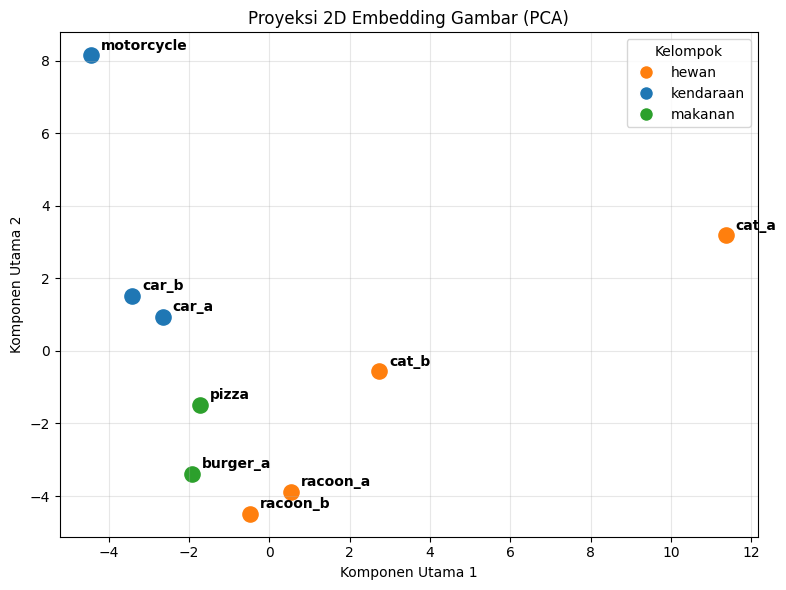

In [50]:
color_map = {"hewan": "tab:orange", "kendaraan": "tab:blue", "makanan": "tab:green"}

plt.figure(figsize=(8, 6))
for (x, y), label, group in zip(coordinates, labels, groups):
    plt.scatter(x, y, s=120, color=color_map[group], label=group)
    plt.annotate(label, (x, y), xytext=(7, 4), textcoords="offset points", fontweight="bold")

handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=c, markersize=10, label=g)
           for g, c in color_map.items()]
plt.legend(handles=handles, title="Kelompok")
plt.title("Proyeksi 2D Embedding Gambar (PCA)")
plt.xlabel("Komponen Utama 1")
plt.ylabel("Komponen Utama 2")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("mgg03_tugas_02.jpg", dpi=150)
plt.show()

### d. Analisis

**Apakah gambar dalam kelompok yang sama cenderung berdekatan?**

Secara umum, gambar yang memiliki objek serupa cenderung berdekatan. Pada grafik, car_a dan car_b terlihat cukup dekat, begitu juga racoon_a dan racoon_b. Namun, cat_a dan cat_b justru cukup berjauhan. Ini menunjukkan bahwa hasil PCA tidak selalu mengelompokkan gambar berdasarkan kategori secara sempurna.

**Gambar mana yang paling jauh dari kelompoknya?**

cat_a terlihat paling jauh dari gambar hewan lainnya. Jaraknya cukup besar dari cat_b maupun racoon_a dan racoon_b. Hal ini bisa disebabkan oleh perbedaan latar belakang, sudut pengambilan gambar, warna, atau fitur visual lainnya.

**Mengapa proyeksi PCA 2D tidak selalu mempertahankan seluruh informasi embedding asli?**

Embedding ResNet50 memiliki 2048 dimensi, sedangkan PCA hanya menampilkannya dalam 2 dimensi. Akibatnya, sebagian informasi dari embedding asli pasti hilang. Jadi, jarak antar gambar pada grafik 2D belum tentu sama dengan jarak sebenarnya dalam ruang embedding 2048 dimensi. PCA lebih cocok digunakan untuk melihat pola atau hubungan data secara sederhana, bukan sebagai representasi lengkap dari embedding.

# Soal 6: Analisis Kritis Representasi Visual

**a. Backbone dan Tugas Baru**

Fitur dari model seperti ResNet50 bisa digunakan untuk tugas lain karena lapisan awal dan tengahnya mempelajari pola visual yang umum, seperti tepi, tekstur, dan bentuk. Ini merupakan konsep transfer learning, di mana fitur yang sudah dipelajari dari ImageNet dapat digunakan untuk tugas seperti mencari gambar yang mirip atau mengelompokkan gambar tanpa melatih model dari awal.

Namun, hasilnya bisa kurang baik jika data yang digunakan sangat berbeda dari ImageNet, misalnya gambar medis atau citra satelit. Dalam kasus seperti ini, model biasanya perlu di-fine-tuning dengan data yang sesuai.

**b. Struktur Lokal dan Abstraksi**

CNN membangun fitur secara bertahap. Lapisan awal biasanya mendeteksi pola sederhana seperti tepi dan perubahan intensitas. Setelah melalui pooling dan beberapa lapisan berikutnya, pola tersebut digabungkan menjadi fitur yang lebih kompleks seperti tekstur dan bagian objek.

Pada bagian akhir, global average pooling merangkum fitur tersebut menjadi sebuah embedding yang mewakili karakteristik gambar secara keseluruhan. Jadi, prosesnya dapat dilihat sebagai perubahan dari piksel sederhana menjadi fitur visual yang semakin kompleks.

**c. Keterbatasan Cosine Similarity**

Cosine similarity tidak selalu sesuai dengan penilaian manusia karena embedding ResNet50 tidak hanya melihat identitas objek. Nilainya juga dapat dipengaruhi oleh warna, tekstur, latar belakang, dan hasil preprocessing seperti resize dan normalisasi.

Selain itu, ResNet50 dilatih untuk klasifikasi ImageNet, bukan untuk mengukur kemiripan berdasarkan persepsi manusia. Akibatnya, dua gambar yang secara visual terlihat berbeda bisa saja memiliki nilai cosine yang cukup tinggi jika memiliki fitur tertentu yang mirip. Jadi, cosine similarity lebih tepat dianggap sebagai ukuran kemiripan dalam ruang fitur model, bukan ukuran mutlak tentang seberapa mirip dua gambar menurut manusia.